# Relatório: classificação de imagens de satélite (EuroSAT RGB) com MLP × CNN × Transfer Learning em CPU

**Disciplina:** Desenvolvimento de Aplicação para Reconhecimento e Interpretação de Imagens
**Alunos:** Eric Costa Ciciliotti e Yuri Martinelli · **Professor:** Humberto Tozetti

**Implementação completa:** [`trabalho_eurosat.ipynb`](trabalho_eurosat.ipynb) · **Link do Colab:** ✍️ (preenchido na entrega)

> **Como este relatório funciona.** Ele é entregue **já executado**. As tabelas abaixo são carregadas dos arquivos CSV exportados pela execução oficial do notebook principal (completa, local, em CPU) e aparecem sem precisar rodar nada. As **figuras** que apoiam as tabelas são as que o próprio notebook principal desenhou nessa mesma execução, lidas do notebook executado, sem redesenho. Nenhum modelo é treinado aqui, e nenhuma métrica é recalculada. Todo número citado no texto vem dessas tabelas ou de uma saída do notebook principal, indicada pela seção entre parênteses (A2, B3 etc.).

### Em resumo

- **Recomendação: Transfer Learning com feature extraction** (MobileNetV2 congelada + uma camada `Dense(10)`). F1-macro no teste de **0,902**, contra 0,778 da CNN própria e 0,498 da MLP. Ele treina na mesma ordem de tempo que a CNN (~160 s contra ~190 s em CPU) e só 12.810 parâmetros são treinados.
- **Fine-tuning** das últimas camadas da MobileNetV2: empatou com a feature extraction e custou ~40–50% mais tempo de treino. Não compensa com 5.000 imagens.
- **MLP:** inadequada para imagens. Ao achatar a imagem, perde a vizinhança entre pixels, fica em underfitting e classifica pela cor média.

| Seção | Conteúdo |
|---|---|
| 1 | Dataset: origem, classes, subconjunto e dificuldades |
| 2 | Decisões tomadas |
| 3 | Métricas finais |
| 4 | Limitações da MLP |
| 5 | Tabela comparativa MLP × CNN × Transfer Learning |
| 6 | Conclusão, recomendação e limitações do estudo |


### Carregamento dos resultados

**O que:** ler os três CSVs que o notebook principal grava em `outputs/` e conferir que eles vêm da execução oficial.
- `resultados_eurosat.csv`: uma linha por variante treinada (11), com todas as métricas.
- `f1_por_classe_eurosat.csv`: o F1 de cada classe, por variante e por conjunto.
- `execucao_eurosat.csv`: de qual execução vieram os números.

**Por quê:** se alguém reexecutar o relatório com arquivos de uma execução rápida de teste (modo smoke) ou de outro split, os `assert` impedem que números errados apareçam como oficiais.


In [1]:
from pathlib import Path

import pandas as pd

PASTA = Path("outputs")
ARQUIVOS = {nome: PASTA / f"{nome}_eurosat.csv" for nome in ["resultados", "f1_por_classe", "execucao"]}
faltando = [caminho.as_posix() for caminho in ARQUIVOS.values() if not caminho.exists()]
if faltando:
    raise FileNotFoundError(
        "Este relatório foi entregue já executado; as tabelas salvas são as da execução oficial. "
        "Para reexecutá-lo (ex.: no Colab), crie a pasta outputs/ ao lado deste notebook e envie para ela "
        f"os CSVs gerados pelo trabalho_eurosat.ipynb. Faltando: {', '.join(faltando)}")

resultados = pd.read_csv(ARQUIVOS["resultados"], index_col="modelo")
f1_classes = pd.read_csv(ARQUIVOS["f1_por_classe"])
execucao = pd.read_csv(ARQUIVOS["execucao"]).iloc[0]

# Só a execução completa oficial vale para o relatório.
assert execucao["modo"] == "completo", "os CSVs são de uma execução smoke"
assert execucao["assinatura_split"] == "25d314761ce3", "os CSVs vêm de outro split"
ESCOLHIDOS = {"MLP": execucao["melhor_mlp"], "CNN própria": execucao["melhor_cnn"],
              "Transfer Learning": execucao["melhor_tl"]}
assert set(ESCOLHIDOS.values()) == set(resultados.index[resultados["na_comparacao_final"]])

BR = {"decimal": ",", "thousands": "."}  # números no padrão brasileiro, como no texto
execucao.rename({
    "n_treino": "imagens de treino", "n_validacao": "imagens de validação",
    "n_teste": "imagens de teste", "assinatura_split": "assinatura do split", "processador": "processador (CPU)",
    "tensorflow": "TensorFlow", "keras": "Keras", "melhor_mlp": "MLP escolhida", "melhor_cnn": "CNN escolhida",
    "melhor_tl": "TL escolhido",
}).to_frame("execução oficial")


,execução oficial
modo,completo
data,2026-11-13 17:56
imagens de treino,5000
imagens de validação,1000
imagens de teste,2000
assinatura do split,25d314761ce3
processador (CPU),Intel(R) Core(TM) i5-10400F CPU @ 2.90GHz
TensorFlow,2.21.0
Keras,3.15.1
MLP escolhida,MLP + ES + augmentation


### Carregamento das figuras

**O que:** ler as figuras direto do notebook principal executado (`trabalho_eurosat.ipynb`, salvo com as saídas da execução oficial). A função `figura` exibe o gráfico que uma célula do notebook principal desenhou, identificada pelo id dela; a seção de origem (A2, B1 etc.) vem na legenda de cada figura.
**Por quê:** nenhuma figura é redesenhada aqui. Elas são as mesmas que o notebook principal gerou na execução que produziu os CSVs, e os `assert` conferem isso pela assinatura do split e pelos modelos escolhidos.

In [2]:
import base64
import json

from IPython.display import Image, display

NOTEBOOK_EXECUTADO = Path("trabalho_eurosat.ipynb")  # salvo já executado (execução oficial)
if not NOTEBOOK_EXECUTADO.exists():
    raise FileNotFoundError(
        "As figuras vêm do notebook principal executado. Para reexecutar este relatório, "
        f"coloque {NOTEBOOK_EXECUTADO.as_posix()} (já executado) na mesma pasta.")
CELULAS = {celula.get("id"): celula for celula in json.loads(NOTEBOOK_EXECUTADO.read_text(encoding="utf-8"))["cells"]}


def texto_impresso(id_celula):
    """Texto que a célula imprimiu na execução (saídas do tipo stream)."""
    return "".join("".join(saida.get("text", "")) for saida in CELULAS[id_celula].get("outputs", []))


# Mesma execução dos CSVs: mesma assinatura do split (A3) e mesmos modelos escolhidos (A6, B1, B3).
assert f"Assinatura do split: {execucao['assinatura_split']}" in texto_impresso("6a5048f7"), "outro split"
escolhas_impressas = texto_impresso("9d7f84e1") + texto_impresso("ea653cbe") + texto_impresso("1745b423")
assert all(f": {nome}\n" in escolhas_impressas for nome in ESCOLHIDOS.values()), "outros modelos escolhidos"


def figura(id_celula, *posicoes):
    """Exibe as figuras que a célula `id_celula` do notebook principal desenhou (todas, ou só as `posicoes`)."""
    pngs = [saida["data"]["image/png"] for saida in CELULAS[id_celula].get("outputs", [])
            if "image/png" in saida.get("data", {})]
    assert pngs, f"a célula {id_celula} não tem figura no notebook executado"
    for posicao in posicoes or range(len(pngs)):
        display(Image(data=base64.b64decode(pngs[posicao])))


## 1. Dataset

**Origem:** o **EuroSAT RGB** ([Helber et al., 2019](https://doi.org/10.1109/JSTARS.2019.2918242)) reúne recortes de imagens do satélite **Sentinel-2**, do programa Copernicus da agência espacial europeia, cobrindo 34 países. São **27.000 imagens de 64×64 pixels** (10 m por pixel, 3 bandas visíveis), rotuladas em **10 classes de uso do solo**. Usamos a versão publicada no [Zenodo (registro 7711810)](https://zenodo.org/records/7711810).

| Classe | Significado | Imagens no dataset |
|---|---|---|
| AnnualCrop · PermanentCrop | Lavoura temporária · lavoura permanente (pomares, vinhedos) | 3.000 · 2.500 |
| Forest · HerbaceousVegetation · Pasture | Floresta · vegetação rasteira · pastagem | 3.000 · 3.000 · 2.000 |
| Highway · Industrial · Residential | Rodovia · área industrial · área residencial | 2.500 · 2.500 · 3.000 |
| River · SeaLake | Rio · mar ou lago | 2.500 · 3.000 |

Todas as imagens têm o mesmo tamanho (64×64, RGB), e a checagem por hash MD5 não encontrou duplicatas (A2).

### Subconjunto usado e por quê

| Conjunto | Imagens | Papel |
|---|---|---|
| Treino | 5.000 | Ajustar os pesos dos modelos |
| Validação | 1.000 | Early stopping e **todas** as escolhas (regularização, variante de cada modelo) |
| Teste | 2.000 | Só para reportar os números finais |

- **Por que um subconjunto:** o enunciado sugere até ~5.000 imagens de treino para caber em CPU. Com o dataset inteiro, cada época custaria ~4× mais, principalmente no Transfer Learning, que processa imagens de 96×96 numa rede profunda. Com 5.000, todo o treino do Transfer Learning levou ~8 min (A3, B4).
- **Regime de poucos dados:** com 5.000 exemplos, fica visível o que cada abordagem consegue extrair de um conjunto pequeno. É aí que a comparação entre aprender do zero (MLP, CNN) e reaproveitar um modelo pré-treinado (Transfer Learning) é mais informativa.
- **Como foi criado:** sorteio **estratificado** por classe (semente 42), em duas etapas: treino × resto, depois validação × teste. Em todos os conjuntos, a proporção de cada classe ficou a no máximo **0,06 ponto percentual** da do dataset completo. Um `assert` garante que nenhuma imagem aparece em dois conjuntos (A3).
- **Por que o teste é o dobro da validação:** reduz o ruído da estimativa final. O erro-padrão no pior caso é de ~1,1 ponto percentual com 2.000 imagens, contra ~1,6 com 1.000 (A3).

### Dificuldades

- **Classes parecidas:** as classes agrícolas (AnnualCrop, PermanentCrop, Pasture, HerbaceousVegetation) diferem por detalhes de textura, e **Highway × River** compartilham a mesma forma, uma faixa linear cortando a imagem (A2).
- **Variação dentro da classe:** iluminação, estação do ano, país e atmosfera mudam bastante o tom da mesma cena. SeaLake, por exemplo, vai do verde-claro ao azul-marinho (A2).
- **Sem orientação fixa:** rodovias, rios e talhões aparecem em qualquer ângulo. Por isso usamos flips e rotações como data augmentation.
- **Desbalanceamento leve:** 3.000 imagens nas maiores classes contra 2.000 em Pasture (razão de 1,5). Isso levou ao split estratificado e ao **F1-macro** como métrica principal: a média do F1 das 10 classes, com o mesmo peso para cada uma (explicado na seção 3).


**Figura 1. Distribuição de imagens por classe** (A2)
**O que:** quantas imagens cada classe tem no dataset completo. **Por quê:** mostra a coluna "Imagens no dataset" da tabela acima: sete classes entre 2.500 e 3.000 imagens e Pasture com 2.000, o desbalanceamento leve (razão 1,5) que levou ao split estratificado e ao F1-macro.

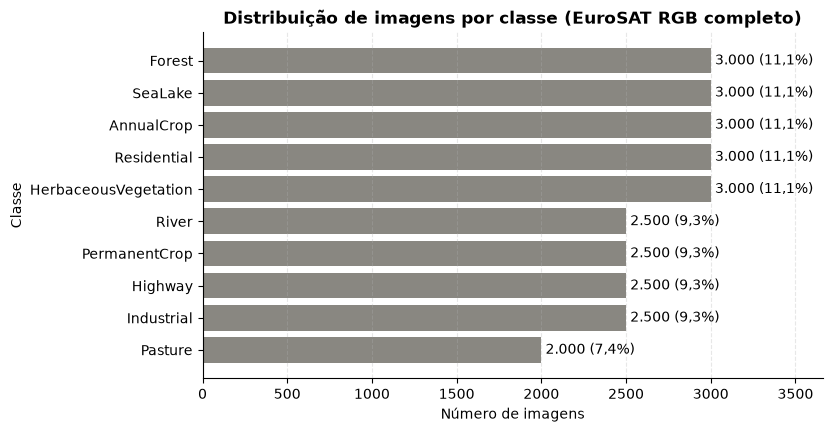

In [3]:
figura("9787d217")


**Figura 2. Exemplos sorteados por classe** (A2)
**O que:** seis imagens de cada classe, uma classe por linha. **Por quê:** é a evidência visual das dificuldades listadas acima. Highway e River aparecem como a mesma faixa linear; AnnualCrop, PermanentCrop, Pasture e HerbaceousVegetation diferem por detalhes de textura; SeaLake varia do verde-claro ao azul-escuro; e nenhuma cena tem orientação fixa.

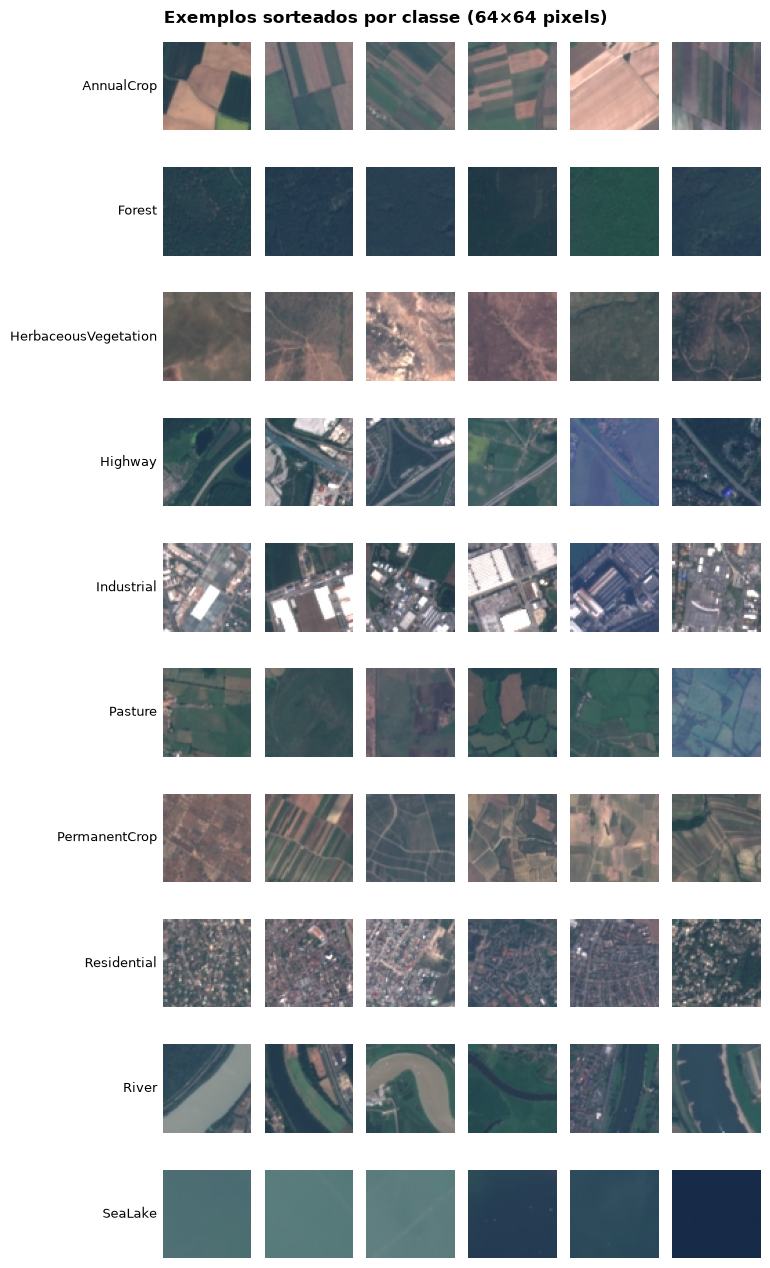

In [4]:
figura("18bee690")


## 2. Decisões tomadas

| Tema | Decisão | Justificativa |
|---|---|---|
| **Split** | 5.000 / 1.000 / 2.000, estratificado, semente 42, feito uma única vez e conferido por hash | Mesmos dados para todos os modelos; sem vazamento entre conjuntos |
| **Pré-processamento** | Dentro de cada modelo: `Rescaling(1/255)` na MLP e na CNN (e `Flatten` na MLP); `Resizing(96)` + escala [−1, 1] na MobileNetV2 | Todos recebem o mesmo array `uint8` 64×64. Equivale a um `Pipeline`: a mesma transformação no treino e no teste, sem estatística calculada nos dados |
| **Perda e otimizador** | Entropia cruzada (`sparse_categorical_crossentropy`) + Adam, lr 1e-3 (1e-5 no fine-tuning); batch 64 | Perda padrão para classificação multiclasse com saída softmax; Adam converge bem sem ajuste fino de lr |
| **Saída e ativações** | `Dense(10, softmax)` em todos os modelos; ReLU nas camadas ocultas da MLP e da CNN | Probabilidades por classe; ReLU não satura e é a mesma nos dois modelos, para uma comparação limpa |
| **MLP** | `Flatten` → 256 → 128 (ReLU) → 10: 3.180.170 parâmetros | 2 camadas ocultas (o enunciado pede 1–2), com capacidade de sobra para o diagnóstico |
| **Regularização (MLP)** | Variantes isoladas: early stopping, dropout 0,3, L2 1e-4 e data augmentation | Medir o efeito de cada técnica separadamente, contra o mesmo baseline |
| **CNN própria** | 3 blocos [Conv 3×3 + MaxPool] com 32 → 64 → 128 filtros, `GlobalAveragePooling`, `Dense(128)`: 111.050 parâmetros | 3 camadas convolucionais (o enunciado pede 2–4); ~29× menos parâmetros que a MLP |
| **Transfer Learning** | MobileNetV2 (ImageNet) congelada + `GlobalAveragePooling` + `Dense(10)`; fine-tuning das 10 convoluções a partir de `block_14_expand`, com as BatchNorm congeladas | Modelo leve recomendado no enunciado. Etapa 1 treina só a camada final; etapa 2 ajusta o último estágio da rede com lr 100× menor. As BatchNorm ficam congeladas porque no Keras 3 o `training=False` não as protege durante o `fit` (demonstrado na B3) |
| **Data augmentation** | Flip horizontal, flip vertical e rotação de até ±90°, só no treino | Cenas de satélite não têm orientação fixa |
| **Early stopping** | Na `val_loss`, restaurando a melhor época: até 40 épocas e paciência 8 (MLP, CNN); 15 por etapa e paciência 4 (TL) | O TL parte de pesos prontos e cada época custa mais. O baseline da MLP roda as 40 épocas sem ES, para mostrar a curva completa: o "antes" do diagnóstico |
| **Diagnóstico pelas curvas** | MLP: **underfitting** predominante (~56% de accuracy no treino), com overfitting moderado só depois da época ~30 (A5). CNN: ajusta bem o treino (~79%) e, com ou sem augmentation, ainda melhorava no fim das 40 épocas, sem overfitting claro (B1). TL: leve overfitting da camada final na etapa 1; o fine-tuning sem augmentation só o aprofundou (B2, B3) | O regime de cada modelo explica o efeito das técnicas: o dropout piora a MLP, que já não ajusta o treino, e o augmentation rende pouco (~+4 pontos) na MLP e na CNN, que não sobreajustam |
| **Métricas** | **F1-macro** (principal), accuracy, precision e recall macro, F1 por classe, matriz de confusão normalizada | Cada classe pesa igual; o desbalanceamento é leve, mas existe |
| **Seleção** | Em cada abordagem, a variante de maior F1-macro na **validação** vai para a comparação; o teste só é reportado | O mesmo processo para todos: nenhum modelo leva vantagem por ter mais opções |
| **Hardware** | Tudo em CPU (GPU desligada); execução oficial local (Intel Core i5-10400F, 12 threads) | O enunciado compara custo em CPU |


## 3. Métricas finais

**O que:** accuracy, precision, recall e F1 (os três em média **macro**) dos três modelos escolhidos, no teste e na validação.

**O que significa "macro":** precision, recall e F1 são calculados **classe por classe**. Por exemplo, o recall de Highway é a fração das rodovias que o modelo encontrou. A versão **macro** é a **média simples** desses 10 valores, com o mesmo peso para cada classe, como o `average="macro"` do sklearn:

> F1-macro = (F1 de AnnualCrop + F1 de Forest + … + F1 de SeaLake) / 10

- **Por que importa:** a accuracy conta imagens, então as classes maiores pesam mais nela. No F1-macro, Pasture (7,4% das imagens) vale tanto quanto AnnualCrop (11,1%). Uma classe com desempenho ruim derruba o F1-macro mesmo quando a accuracy continua alta. Por isso ele é a métrica principal do trabalho.
- **Alternativa não usada:** a média **ponderada** (`average="weighted"`) pesa cada classe pelo número de imagens e por isso fica mais próxima da accuracy.

**Como ler:** o **teste** é o desempenho reportado. A validação aparece porque foi ela que escolheu cada modelo; por isso é levemente otimista para o vencedor de cada abordagem.


In [5]:
metricas = {"accuracy": "accuracy", "precision": "precision_macro", "recall": "recall_macro", "F1": "f1_macro"}
finais = resultados.loc[list(ESCOLHIDOS.values())]
tabela_metricas = pd.DataFrame(
    {(conjunto, nome): finais[f"{prefixo}_{coluna}"].to_numpy()
     for conjunto, prefixo in [("teste", "test"), ("validação", "val")] for nome, coluna in metricas.items()},
    index=pd.Index([f"{abordagem} ({variante})" for abordagem, variante in ESCOLHIDOS.items()], name="modelo"))
tabela_metricas.style.format(precision=3, **BR)


**F1 por classe no teste.** O F1-macro é uma média; a tabela abaixo mostra onde cada modelo acerta e erra, com as classes ordenadas da mais difícil para a mais fácil segundo o Transfer Learning.


In [6]:
f1_teste = f1_classes[f1_classes["conjunto"] == "test"].pivot(index="classe", columns="modelo", values="f1")
f1_finais = f1_teste[list(ESCOLHIDOS.values())].set_axis(list(ESCOLHIDOS), axis=1)
f1_finais = f1_finais.sort_values("Transfer Learning")
f1_finais.style.format(precision=2, **BR).background_gradient(cmap="Blues", vmin=0, vmax=1)


,MLP,CNN própria,Transfer Learning
classe,,,
Highway,"0,22","0,43","0,83"
Pasture,"0,46","0,78","0,84"
PermanentCrop,"0,36","0,65","0,85"
River,"0,48","0,70","0,86"
HerbaceousVegetation,"0,37","0,74","0,86"
AnnualCrop,"0,51","0,87","0,92"
Industrial,"0,60","0,85","0,95"
Forest,"0,77","0,91","0,96"
Residential,"0,55","0,92","0,97"


**Figuras 3 e 4. Matrizes de confusão no teste: CNN própria e Transfer Learning** (B1, B2)
**O que:** as matrizes dos dois melhores modelos, normalizadas por linha: cada linha é a classe verdadeira e soma 1, então a diagonal é o recall de cada classe. **Por quê:** mostram de onde vêm os F1 por classe da tabela acima e para onde vão os erros citados na interpretação abaixo.
**Como ler:** na CNN, um quarto das rodovias vira rio (Highway → River 0,25), e só 0,35 delas são acertadas. No TL, esse erro cai para 0,10 e o recall de Highway sobe para 0,80; o maior resíduo passa a ser PermanentCrop → HerbaceousVegetation (0,13). A matriz da MLP aparece na seção 4.

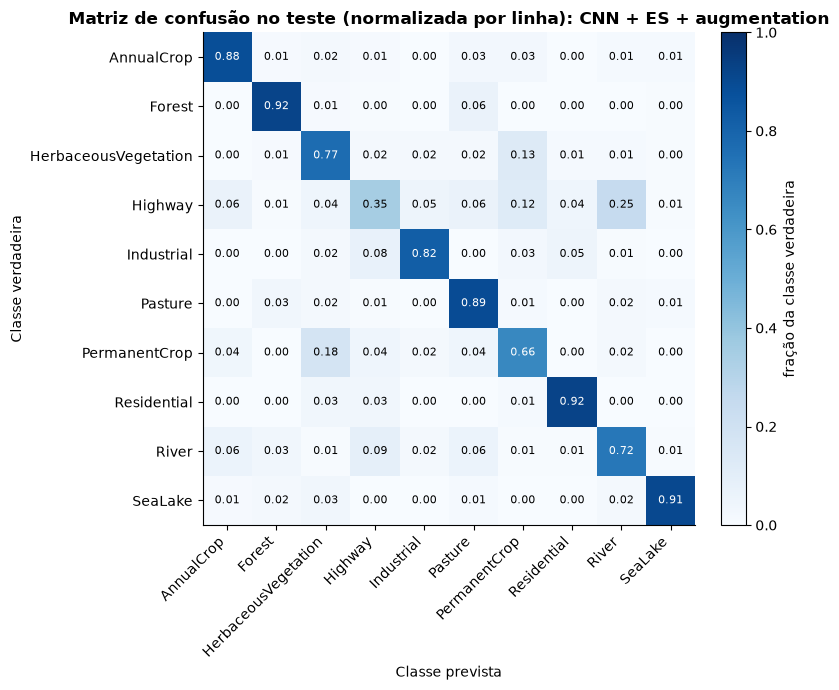

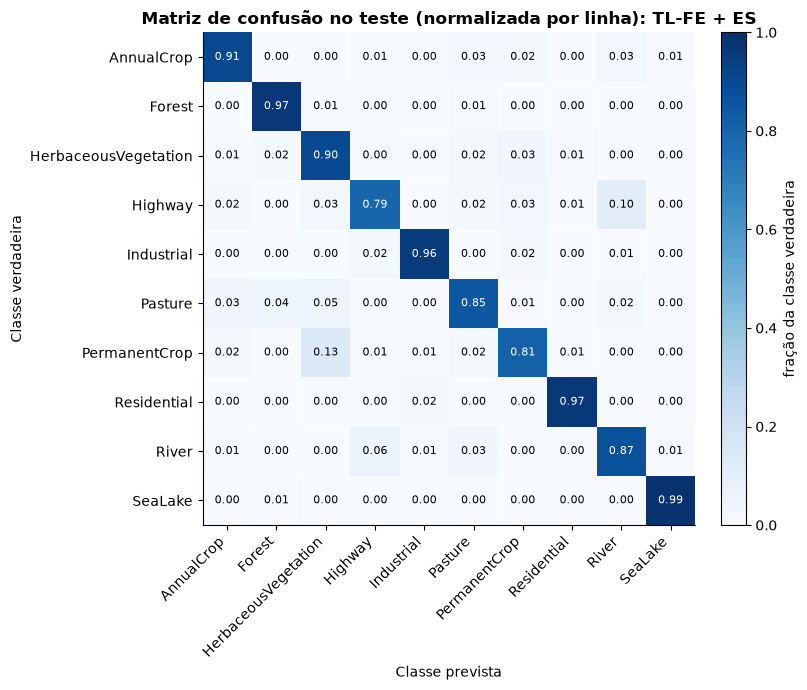

In [7]:
figura("e49b6856")  # CNN própria (CNN + ES + augmentation)
figura("2fc0ceb1")  # Transfer Learning (TL-FE + ES)


**Interpretação das métricas:**
- **Ranking claro:** Transfer Learning > CNN > MLP em todas as métricas. No teste, o F1-macro vai de **0,498** (MLP) a **0,778** (CNN) e a **0,902** (TL), vãos de +28 e +12 pontos, muito acima do ruído de amostragem (~1,1 a 1,6 ponto, seção 1).
- **Precision ≈ recall ≈ F1** em cada modelo: nenhum deles ganha trocando um tipo de erro pelo outro (por exemplo, prevendo sempre a mesma classe).
- **Accuracy ≈ F1-macro** (0,518 × 0,498 na MLP; 0,791 × 0,778 na CNN; 0,906 × 0,902 no TL): vão de ~2 pontos na MLP, ~1,4 na CNN e ~0,4 no TL. Como as classes são quase balanceadas, a accuracy não esconde nenhuma classe esquecida.
- **Por classe:** o TL é melhor ou igual à CNN, e a CNN à MLP, em **todas as 10 classes**. As **mesmas 5 classes** são as mais difíceis para os três modelos: Highway, PermanentCrop, River, HerbaceousVegetation e Pasture. São os pares de aparência parecida apontados na análise exploratória (faixas lineares e vegetações). A MLP desaba justamente nelas (F1 de 0,22 em Highway).
- **Desbalanceamento:** há uma correlação a considerar, porque 4 das 5 classes mais difíceis estão entre as 5 menores. Três evidências indicam que a causa é a **semelhança visual**, não o tamanho:
  - a diferença de exemplos é pequena (370 contra 556 imagens de treino por classe, no máximo 1,5×);
  - Industrial, do mesmo tamanho de Highway, chega a 0,95 no TL, enquanto Highway é a pior nos três modelos;
  - no diagnóstico da MLP baseline (A5), Pasture, a menor classe, foi prevista **mais** vezes do que existe (93 previsões para 74 imagens reais na validação), o oposto do que o desbalanceamento causaria.

  Por isso não foi preciso usar pesos de classe nem reamostragem.
- **Principais confusões do modelo recomendado** (teste, B2): PermanentCrop → HerbaceousVegetation (13,4% das imagens de PermanentCrop) e Highway → River (10,3%). Na CNN, Highway → River chegava a 24,9% (Figuras 3 e 4).


## 4. Limitações da MLP para este problema

**O que:** as cinco variantes da MLP (o baseline e as quatro regularizações), ao lado das duas variantes da CNN.
**Por quê:** mostra que nenhuma técnica de regularização tirou a MLP do patamar de ~0,5 de F1. O limite está na própria representação, não no ajuste.


In [8]:
linhas_mlp = resultados.index[resultados["abordagem"] != "Transfer Learning"].tolist()  # MLPs e as duas CNNs
tabela_mlp = resultados.loc[linhas_mlp, ["val_f1_macro", "test_f1_macro", "epocas", "pesos_da_epoca", "params_totais"]]
tabela_mlp = tabela_mlp.rename(columns={
    "val_f1_macro": "F1-macro val", "test_f1_macro": "F1-macro teste", "epocas": "épocas",
    "pesos_da_epoca": "pesos da época", "params_totais": "parâmetros"})
tabela_mlp.insert(0, "papel", ["antes (sem early stopping)" if nome == "MLP baseline" else
                               "escolhida" if nome in ESCOLHIDOS.values() else "" for nome in tabela_mlp.index])
(tabela_mlp.style
 .format(precision=3, subset=["F1-macro val", "F1-macro teste"], **BR)
 .format(precision=0, subset=["parâmetros"], **BR))


,papel,F1-macro val,F1-macro teste,épocas,pesos da época,parâmetros
modelo,,,,,,
MLP baseline,antes (sem early stopping),"0,482","0,477",40,40,3.180.170
MLP + ES,,"0,469","0,479",39,31,3.180.170
MLP + ES + dropout,,"0,339","0,340",40,37,3.180.170
MLP + ES + L2,,"0,489","0,496",40,37,3.180.170
MLP + ES + augmentation,escolhida,"0,507","0,498",40,39,3.180.170
CNN + ES,,"0,761","0,758",40,37,111.050
CNN + ES + augmentation,escolhida,"0,797","0,778",40,40,111.050


**Figura 5. MLP: F1-macro na validação antes × depois da regularização** (A6)
**O que:** a coluna "F1-macro val" das cinco MLPs da tabela acima, em barras; a verde é a escolhida. **Por quê:** deixa visível o patamar de ~0,5: early stopping, L2 e augmentation ficam a poucos centésimos do baseline, e só o dropout se afasta, para baixo.

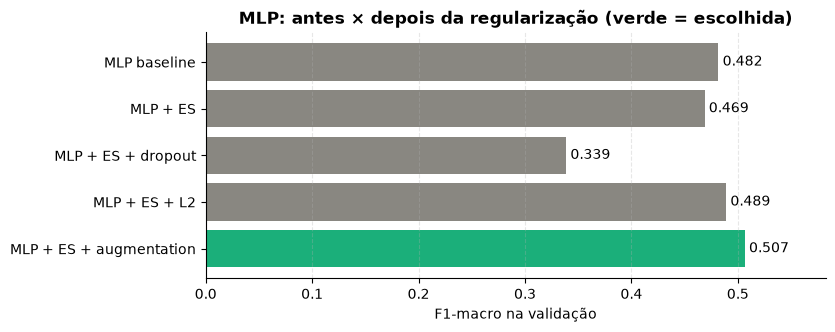

In [9]:
figura("9d7f84e1")


**Figura 6. Curvas de treino × validação da MLP baseline** (A5)
**O que:** loss e accuracy por época nas 40 épocas do baseline, sem early stopping (treino em azul, validação em laranja). **Por quê:** é a evidência do **underfitting** citado na tabela de limitações abaixo: a accuracy de treino fica em torno de 0,56 nas últimas épocas e a loss de treino cai cada vez mais devagar, mesmo com 3,18 milhões de parâmetros. O vão entre treino e validação só cresce um pouco depois da época ~30 (overfitting moderado), e a validação oscila bastante de uma época para a outra.

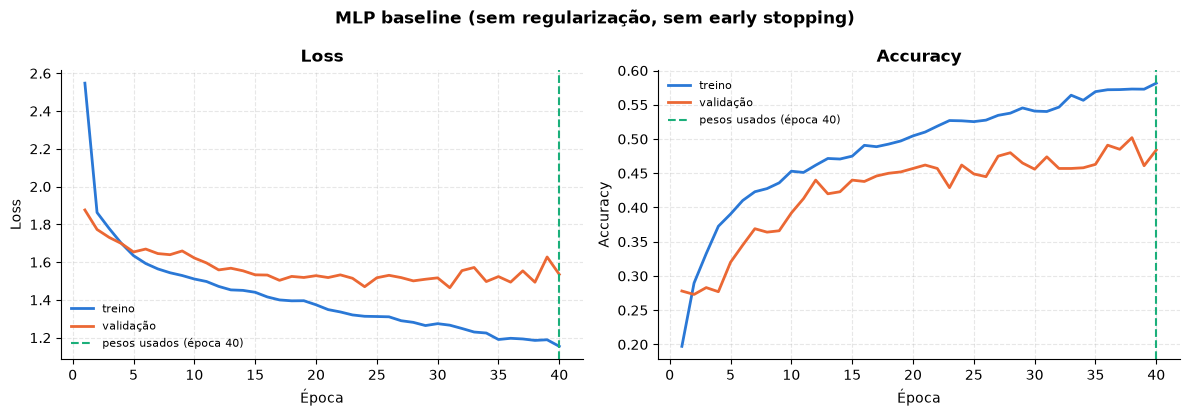

In [10]:
figura("1fc86b25")


**Figura 7. Matriz de confusão da MLP baseline no teste** (A5)
**O que:** a mesma matriz normalizada por linha das Figuras 3 e 4, para o baseline da MLP. É a matriz analisada no notebook principal; a da MLP escolhida não foi desenhada, mas tem o mesmo tipo de erro, entre classes de cor parecida (B1). **Por quê:** sustenta a primeira limitação da tabela abaixo. Os erros se espalham entre classes de **cor média** parecida: os cinzas urbanos (Residential, HerbaceousVegetation, Highway) se misturam, e as classes escuras se misturam (Forest → SeaLake, SeaLake → Pasture, Pasture → River). Compare com a diagonal muito mais forte das Figuras 3 e 4.

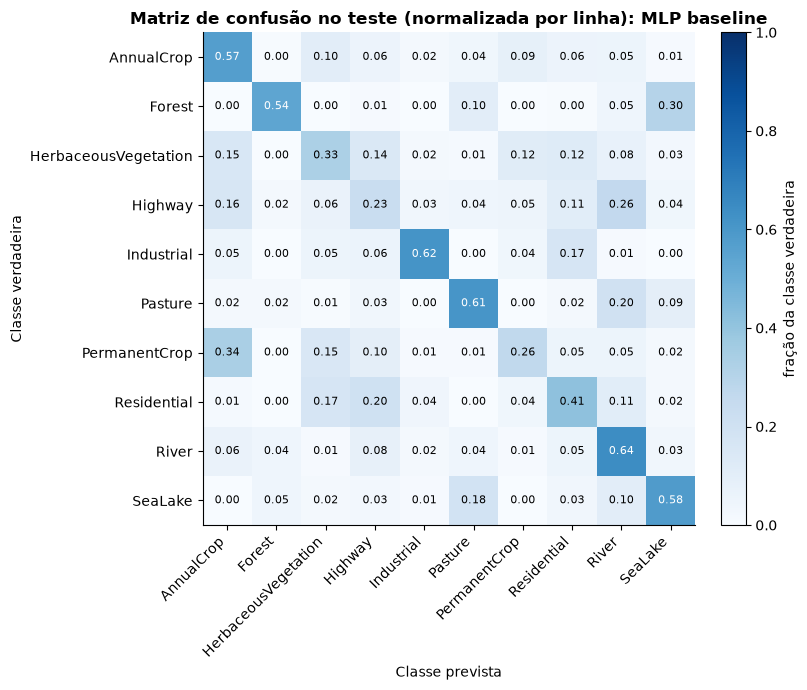

In [11]:
figura("ac1d7c76")


**Figuras 8 e 9. Curvas de treino × validação da CNN, sem e com augmentation** (B1)
**O que:** as curvas das duas CNNs da tabela acima. **Por quê:** mostram que o regime da CNN é outro. Ela ajusta bem o treino (~0,79 de accuracy, contra ~0,56 da MLP na Figura 6) e, com ou sem augmentation, ainda melhorava no fim das 40 épocas, sem overfitting claro; a variante sem augmentation tem só um episódio de instabilidade por volta da época 20. Por isso o augmentation rende pouco aqui (~+4 pontos), como na MLP: não há overfitting para ele corrigir.

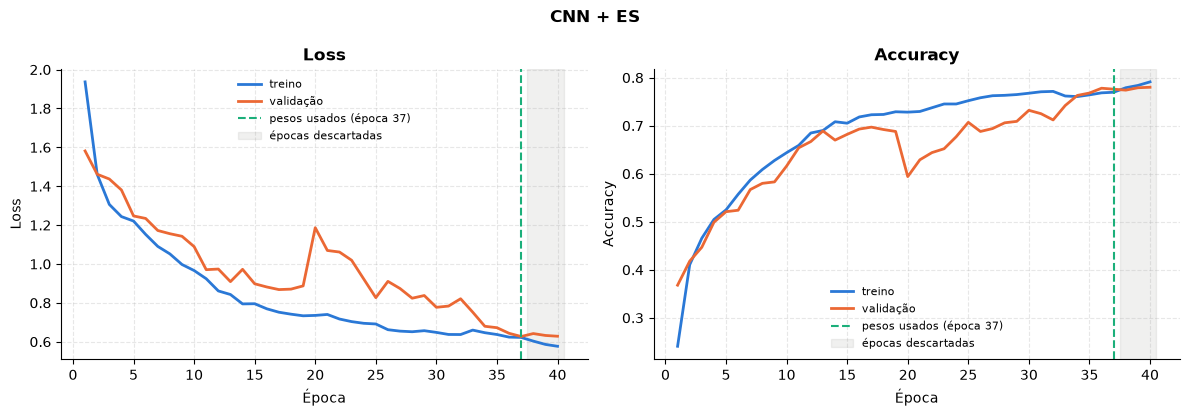

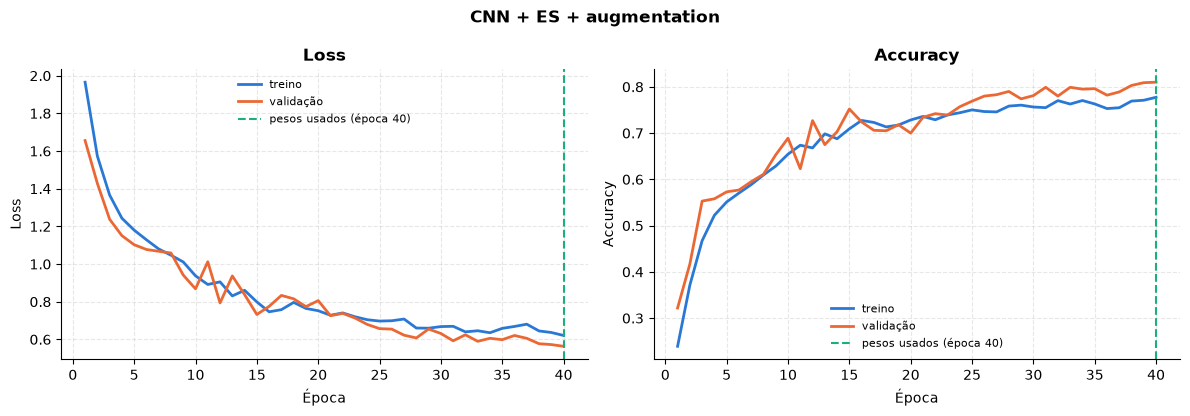

In [12]:
figura("ef72d46f")  # CNN + ES e CNN + ES + augmentation


| Limitação | Evidência (notebook principal) |
|---|---|
| **Joga fora a estrutura espacial.** O `Flatten` transforma a imagem 64×64×3 em 12.288 números independentes; a MLP não sabe que pixels vizinhos formam uma estrada ou um talhão | Os erros seguem a **cor média**: cinzas urbanos se confundem entre si, e as classes escuras se misturam (Forest → SeaLake, SeaLake → Pasture, Pasture → River) (A5, Figura 7). A CNN, que enxerga vizinhanças, derruba essas confusões para no máximo ~0,06 (B1) |
| **Sem invariância à posição.** A mesma rodovia deslocada alguns pixels ativa entradas totalmente diferentes | A CNN, que aplica os mesmos filtros em toda a imagem, ganha **+28 pontos** de F1 no teste com os mesmos dados e o mesmo protocolo (tabela acima) |
| **Underfitting apesar de muitos parâmetros.** O problema não é falta de capacidade | 3.180.170 parâmetros e só ~56% de accuracy no próprio treino (A5). A CNN tem 111.050 parâmetros (~29× menos) e ajusta bem mais |
| **Regularização não resolve** | Todas as variantes ficam entre 0,47 e 0,51 de F1 na validação, exceto o dropout, que piora para 0,34 (tabela acima e Figura 5). Em modelo com underfitting, regularizar não tem o que corrigir (A6). O augmentation rende ~+4 pontos tanto na MLP quanto na CNN; trocar a MLP pela CNN rende +29 (0,507 → 0,797) |
| **Custo preso à resolução.** Um peso por pixel × neurônio | 98,9% dos parâmetros estão na 1ª camada (3.145.984). Com imagens de 128×128, só essa camada teria 4× mais (A6) |

**Leitura da tabela:** o baseline não era candidato: é o "antes" do diagnóstico, treinado sem early stopping. Entre as candidatas, a escolha usa só a validação; as diferenças de teste entre elas (0,479 a 0,498, fora o dropout) estão no nível do ruído.


## 5. Tabela comparativa: MLP × CNN própria × Transfer Learning

**O que:** os três modelos escolhidos, com os quatro itens pedidos no enunciado (accuracy, F1-score, tempo de treinamento e número de parâmetros), mais parâmetros treináveis, épocas e tempo de inferência.
**Comparação justa:** mesmo split, mesmo pré-processamento dentro do modelo, mesma perda, otimizador, batch e critério de parada, mesmo processo de seleção pela validação, tudo em CPU. As diferenças assumidas estão na seção B4 do notebook principal:
- o TL tem orçamento de 15 épocas por etapa e paciência 4, contra 40 e 8;
- o fine-tuning usa lr 1e-5;
- o TL processa as imagens em 96×96 internamente;
- o pré-treino no ImageNet não entra na conta.


In [13]:
tabela_final = pd.DataFrame({
    "variante": list(ESCOLHIDOS.values()),
    "accuracy (teste)": finais["test_accuracy"].to_numpy(),
    "F1-macro (teste)": finais["test_f1_macro"].to_numpy(),
    "tempo de treino (s)": finais["tempo_treino_s"].to_numpy(),
    "épocas": finais["epocas"].to_numpy(),
    "tempo por época (s)": (finais["tempo_treino_s"] / finais["epocas"]).to_numpy(),
    "parâmetros totais": finais["params_totais"].to_numpy(),
    "parâmetros treináveis": finais["params_treinaveis"].to_numpy(),
    "inferência (ms/imagem)": finais["tempo_inferencia_ms_por_imagem"].to_numpy(),
}, index=pd.Index(list(ESCOLHIDOS), name="abordagem"))
(tabela_final.style
 .format(precision=3, subset=["accuracy (teste)", "F1-macro (teste)"], **BR)
 .format(precision=0, subset=["tempo de treino (s)", "parâmetros totais", "parâmetros treináveis"], **BR)
 .format(precision=1, subset=["tempo por época (s)"], **BR)
 .format(precision=2, subset=["inferência (ms/imagem)"], **BR))


,variante,accuracy (teste),F1-macro (teste),tempo de treino (s),épocas,tempo por época (s),parâmetros totais,parâmetros treináveis,inferência (ms/imagem)
abordagem,,,,,,,,,
MLP,MLP + ES + augmentation,"0,518","0,498",81,40,"2,0",3.180.170,3.180.170,"0,07"
CNN própria,CNN + ES + augmentation,"0,791","0,778",189,40,"4,7",111.050,111.050,"0,28"
Transfer Learning,TL-FE + ES,"0,906","0,902",162,15,"10,8",2.270.794,12.810,"1,76"


**Figura 10. Desempenho × custo em CPU** (B4)
**O que:** o F1-macro no teste contra o tempo de treino (à esquerda) e o tempo de inferência por imagem (à direita, em escala logarítmica). Os três modelos da tabela acima estão em verde; as demais variantes de cada abordagem, em cinza. **Por quê:** é a tabela comparativa em forma de gráfico. O canto superior esquerdo é o ideal: no treino, o TL fica na mesma faixa de tempo da CNN (até um pouco à esquerda) com F1 bem maior; na inferência, a ordem se inverte e o TL é o mais caro. Os pontos cinza à direita do TL, no painel de treino, são o fine-tuning: mais tempo para o mesmo F1.

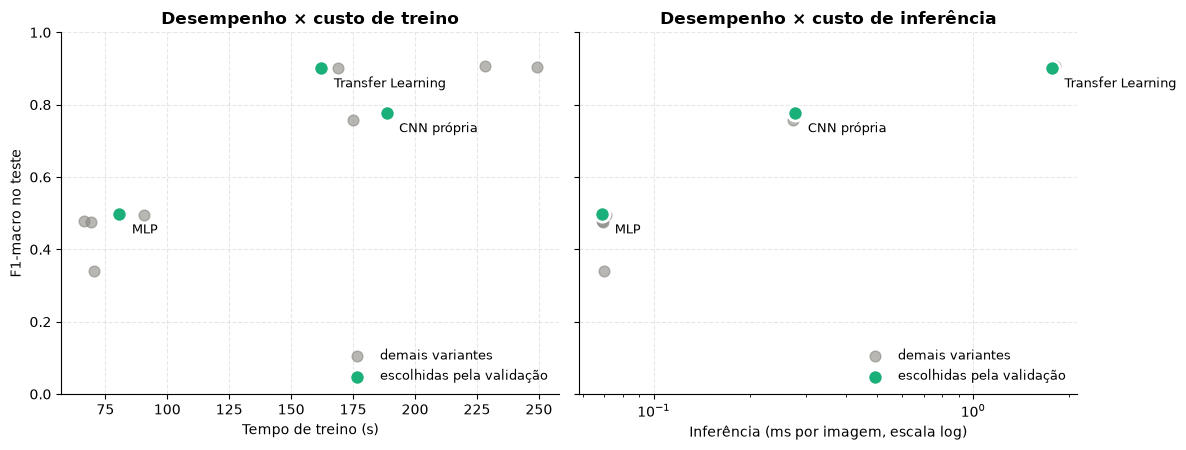

In [14]:
figura("59cee753")


**As duas etapas do Transfer Learning.** O enunciado pede as duas etapas: feature extraction (base congelada, só a camada final treina) e fine-tuning (últimas camadas da base descongeladas, lr baixa). Cada etapa foi treinada com e sem augmentation; o tempo e as épocas do fine-tuning somam as duas etapas.


In [15]:
tl = resultados[resultados["abordagem"] == "Transfer Learning"]
tabela_tl = pd.DataFrame({
    "etapa": ["1: feature extraction" if "FE" in nome else "2: fine-tuning" for nome in tl.index],
    "F1-macro val": tl["val_f1_macro"], "F1-macro teste": tl["test_f1_macro"],
    "parâmetros treináveis": tl["params_treinaveis"], "tempo de treino (s)": tl["tempo_treino_s"],
    "escolhido": ["✔" if escolhido else "" for escolhido in tl["na_comparacao_final"]],
})
(tabela_tl.style
 .format(precision=3, subset=["F1-macro val", "F1-macro teste"], **BR)
 .format(precision=0, subset=["parâmetros treináveis", "tempo de treino (s)"], **BR))


,etapa,F1-macro val,F1-macro teste,parâmetros treináveis,tempo de treino (s),escolhido
modelo,,,,,,
TL-FE + ES,1: feature extraction,"0,916","0,902",12.810,162,✔
TL-FE + ES + augmentation,1: feature extraction,"0,900","0,900",12.810,169,
TL-FT + ES,2: fine-tuning,"0,915","0,906",1.523.530,228,
TL-FT + ES + augmentation,2: fine-tuning,"0,912","0,904",1.523.530,249,


**Figura 11. Transfer Learning: etapa 1 (feature extraction) seguida da etapa 2 (fine-tuning), sem augmentation** (B3)
**O que:** as curvas do TL escolhido (etapa 1) e do fine-tuning que parte dele, no mesmo gráfico. A linha pontilhada marca a troca de etapa, as linhas verdes marcam os pesos usados em cada etapa e a área cinza mostra as épocas descartadas pelo early stopping. **Por quê:** sustenta a tabela acima e a interpretação abaixo. Na etapa 1, a validação passa de 0,86 de accuracy já na 1ª época e estaciona em ~0,92. Na etapa 2, a loss de treino continua caindo, mas a `val_loss` sobe desde a 1ª época: o fine-tuning aprofunda o overfitting em vez de melhorar a validação.

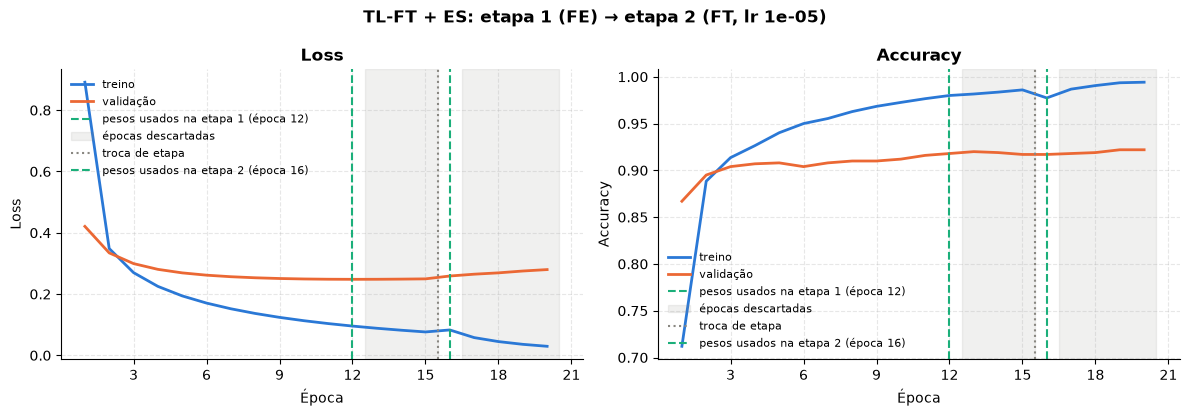

In [16]:
figura("497e74e6", 0)  # TL-FT + ES (a variante com augmentation está na B3 do notebook principal)


**Interpretação:**
- **Desempenho:** o TL ganha da CNN por **12 pontos** de F1 e da MLP por **40**.
- **Custo de treino em CPU:** o TL e a CNN treinam na **mesma ordem de tempo** (~160 s e ~190 s; o TL foi até um pouco mais rápido). A CNN roda 40 épocas de ~4,7 s; o TL, 15 épocas de ~11 s, porque cada época passa as 5.000 imagens pela MobileNetV2 inteira. A MLP é a mais barata (~80 s), mas fica muito abaixo. Os tempos variam entre execuções e entre máquinas, então valem em ordem de grandeza (Figura 10).
- **Parâmetros:** a MLP tem o maior número (3,18 milhões) e o pior resultado. O TL tem 2,27 milhões no total, mas treina só **12.810**, ~9× menos que a CNN. O que conta é o **viés indutivo** (a convolução enxerga vizinhanças) e o conhecimento pré-treinado, não a quantidade de parâmetros.
- **Inferência e tamanho:** são os únicos pontos em que o TL perde. O modelo inteiro é ~20× maior que a CNN (2,27 milhões de parâmetros contra 111 mil). São ~1,8 ms por imagem, ~6× a CNN e ~25× a MLP, porque cada previsão atravessa a MobileNetV2 inteira. Em valores absolutos, classificar as 2.000 imagens do teste leva ~3,5 s em CPU.
- **Etapas do TL:** o fine-tuning **empatou** com a feature extraction (F1 de validação 0,916 × 0,915, diferença de 0,0013), com ~40–50% mais tempo de treino e ~119× mais parâmetros treináveis (1.523.530). Sem augmentation, ele só aprofundou o overfitting: a loss de validação subiu desde a 1ª época (B3, Figura 11). Pelo critério da validação, segue a etapa 1, que também é a mais simples e mais barata. No teste, o fine-tuning aparece 0,004 à frente (0,906 × 0,902): dentro do ruído e, pelo protocolo, sem influência na escolha.


## 6. Conclusão e recomendação

**Recomendamos o Transfer Learning com feature extraction**: a MobileNetV2 pré-treinada no ImageNet, congelada, com uma única camada `Dense(10, softmax)` treinada sobre as features dela.

| Critério do enunciado | O que os resultados mostram |
|---|---|
| **Resultado** | F1-macro no teste de 0,902, contra 0,778 da CNN e 0,498 da MLP. O ranking é o mesmo na validação e no teste, e os vãos estão muito acima do ruído |
| **Custo computacional em CPU** | Treino na mesma ordem de tempo da CNN (~160 s × ~190 s), com o treino mais simples dos três (só a camada final). A inferência é ~6× mais lenta que a da CNN, mas ainda leva poucos segundos para milhares de imagens |
| **Tamanho do dataset** | É o fator decisivo. Com 5.000 imagens, filtros aprendidos do zero ficam limitados: a CNN ainda melhorava na 40ª e última época, 12 pontos abaixo do TL. As features aprendidas em ~1,3 milhão de imagens do ImageNet transferem bem, e o fine-tuning não acrescentou nada neste volume |

**Quando escolher outra abordagem:**
- **CNN própria:** se a inferência for o gargalo (tempo real, dispositivo embarcado) ou se não for possível usar pesos pré-treinados. O preço é ~12 pontos de F1, concentrados em Highway, PermanentCrop e River.
- **Fine-tuning:** não se paga com 5.000 imagens. Com o dataset completo (~27 mil), talvez valesse; é uma hipótese, não foi testada.
- **MLP:** não é recomendada para imagens. Ela perde a estrutura espacial no `Flatten` e fica em underfitting (seção 4).

### Limitações do estudo

| Limitação | Efeito nas conclusões |
|---|---|
| **Uma única semente e uma única máquina** | Pequenas variações numéricas entre CPUs mudam a trajetória do treino. Os vãos entre abordagens (12 e 28 pontos) estão muito acima do ruído, mas diferenças de 1–2 pontos entre variantes da mesma abordagem não devem ser lidas como ranking |
| **Correlação espacial** | A checagem por hash só remove duplicatas exatas. Recortes vizinhos da mesma região podem cair em conjuntos diferentes, o que deixa as métricas um pouco otimistas para **todos** os modelos; o ranking não deve mudar |
| **Tempos ruidosos** | Os tempos variam entre execuções e entre máquinas, e cada variante foi medida uma vez; a comparação de custo vale em ordem de grandeza |
| **Orçamento de 40 épocas** | As melhores épocas da MLP e da CNN foram a 39ª e a 40ª; com mais épocas talvez ganhassem um pouco, mas não o bastante para fechar 12 pontos |
| **Pares ambíguos em 64×64 RGB** | Highway ↔ River e PermanentCrop → HerbaceousVegetation continuam sendo os maiores erros mesmo no melhor modelo, inclusive depois do fine-tuning. Mais resolução ou as bandas infravermelhas do EuroSAT multiespectral ficaram fora do escopo |
| **Pré-treino fora da conta** | O custo de treinar a MobileNetV2 no ImageNet não entra na comparação; ele foi pago por quem publicou os pesos |
